# Final Assignment: Statistics with Python

Analysis of the Boston housing dataset (U.S. Census Service) to present insights to higher management.

## Task 1: Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

%matplotlib inline
sns.set_style('whitegrid')

In [2]:
urls = [
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/boston_housing.csv',
    'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv',
]
boston_df = None
for u in urls:
    try:
        boston_df = pd.read_csv(u)
        break
    except Exception as e:
        continue
boston_df.columns = [c.upper() for c in boston_df.columns]
boston_df = boston_df.drop(columns=[c for c in boston_df.columns if c.startswith('UNNAMED')])
boston_df['CHAS'] = boston_df['CHAS'].astype(float)
boston_df.shape

(506, 14)

## Task 2: Explore the DataFrame

In [3]:
# First 5 rows of the DataFrame
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [4]:
# Data types of each column
boston_df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

In [5]:
# Check for missing values
boston_df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [6]:
# Check for duplicated entries
boston_df.duplicated().sum()

np.int64(0)

In [7]:
# Descriptive statistics
boston_df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [8]:
# Correlation matrix
boston_df.corr()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,-0.385064,0.455621,-0.388305
ZN,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,0.175520,-0.412995,0.360445
INDUS,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,-0.356977,0.603800,-0.483725
CHAS,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,0.048788,-0.053929,0.175260
NOX,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,-0.380051,0.590879,-0.427321
RM,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,0.128069,-0.613808,0.695360
AGE,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,-0.273534,0.602339,-0.376955
DIS,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,0.291512,-0.496996,0.249929
RAD,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,-0.444413,0.488676,-0.381626
TAX,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,-0.441808,0.543993,-0.468536


In [9]:
# Display the entirety of the DataFrame
print(boston_df.to_string())

         CRIM     ZN  INDUS  CHAS     NOX     RM    AGE      DIS  RAD  TAX  PTRATIO       B  LSTAT  MEDV
0     0.00632   18.0   2.31   0.0  0.5380  6.575   65.2   4.0900    1  296     15.3  396.90   4.98  24.0
1     0.02731    0.0   7.07   0.0  0.4690  6.421   78.9   4.9671    2  242     17.8  396.90   9.14  21.6
2     0.02729    0.0   7.07   0.0  0.4690  7.185   61.1   4.9671    2  242     17.8  392.83   4.03  34.7
3     0.03237    0.0   2.18   0.0  0.4580  6.998   45.8   6.0622    3  222     18.7  394.63   2.94  33.4
4     0.06905    0.0   2.18   0.0  0.4580  7.147   54.2   6.0622    3  222     18.7  396.90   5.33  36.2
5     0.02985    0.0   2.18   0.0  0.4580  6.430   58.7   6.0622    3  222     18.7  394.12   5.21  28.7
6     0.08829   12.5   7.87   0.0  0.5240  6.012   66.6   5.5605    5  311     15.2  395.60  12.43  22.9
7     0.14455   12.5   7.87   0.0  0.5240  6.172   96.1   5.9505    5  311     15.2  396.90  19.15  27.1
8     0.21124   12.5   7.87   0.0  0.5240  5.631  100.0

## Task 3: Descriptive statistics and visualizations

### 3.1 Scatter plot: relationship between NOX and INDUS

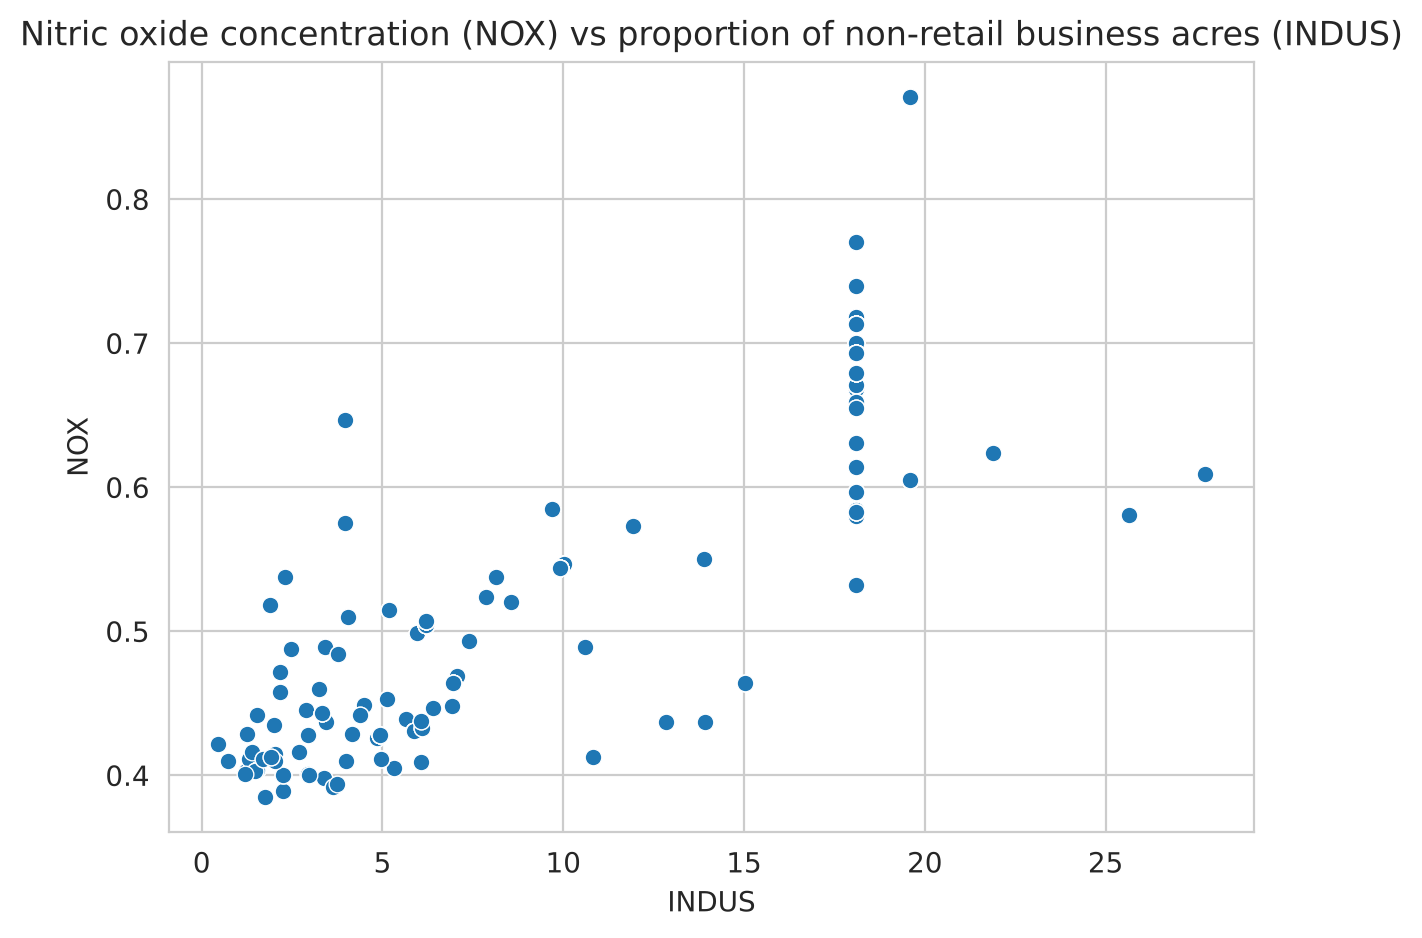

In [10]:
plt.figure(figsize=(7,5))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
plt.title('Nitric oxide concentration (NOX) vs proportion of non-retail business acres (INDUS)')
plt.show()

**Interpretation:** NOX increases as INDUS increases, a positive relationship. Towns with more industrial land tend to have higher nitric oxide concentrations.

### 3.2 Histogram: Pupil to teacher ratio (PTRATIO)

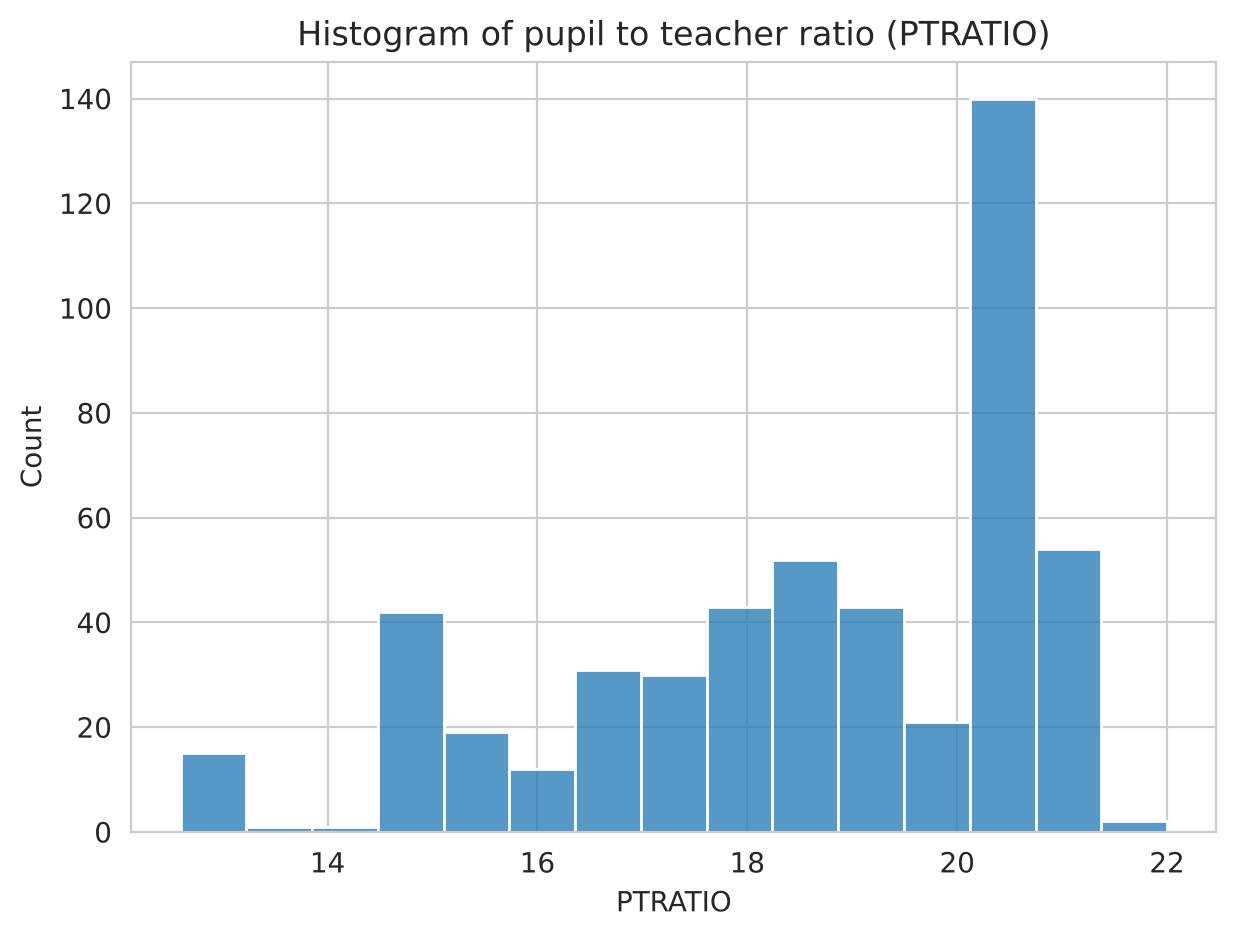

In [11]:
plt.figure(figsize=(7,5))
sns.histplot(boston_df['PTRATIO'], bins=15)
plt.title('Histogram of pupil to teacher ratio (PTRATIO)')
plt.show()

**Interpretation:** The distribution is not symmetric. Most towns fall between about 14 and 22 pupils per teacher, with a noticeable peak around 20 to 21.

### 3.3 Histogram: Median value of owner-occupied homes (MEDV)

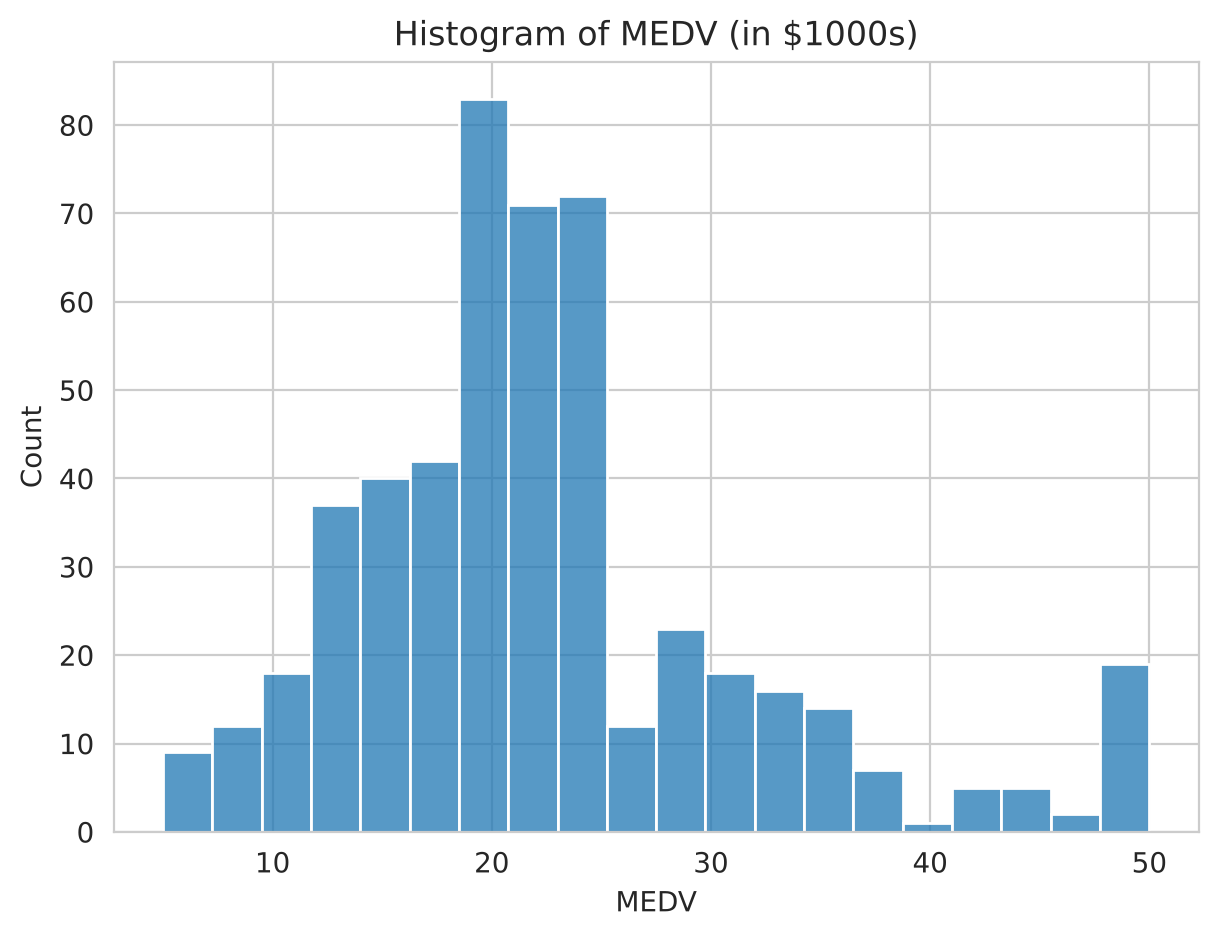

In [12]:
plt.figure(figsize=(7,5))
sns.histplot(boston_df['MEDV'], bins=20)
plt.title('Histogram of MEDV (in $1000s)')
plt.show()

**Interpretation:** MEDV is roughly bell-shaped but right-skewed, with a cluster of capped values at 50 (the maximum).

### 3.4 Boxplot: MEDV

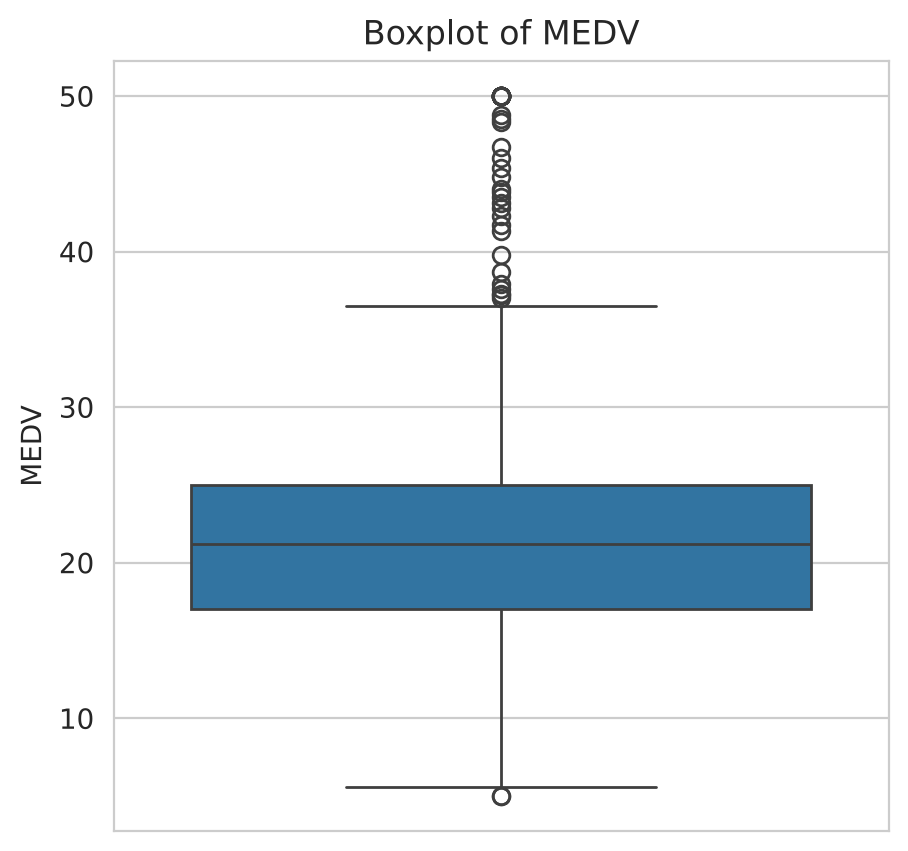

In [13]:
plt.figure(figsize=(5,5))
sns.boxplot(y='MEDV', data=boston_df)
plt.title('Boxplot of MEDV')
plt.show()

**Interpretation:** The median is around 21 and there are several upper outliers (high-priced homes) above roughly 37.

### 3.5 Boxplot: MEDV vs Age group

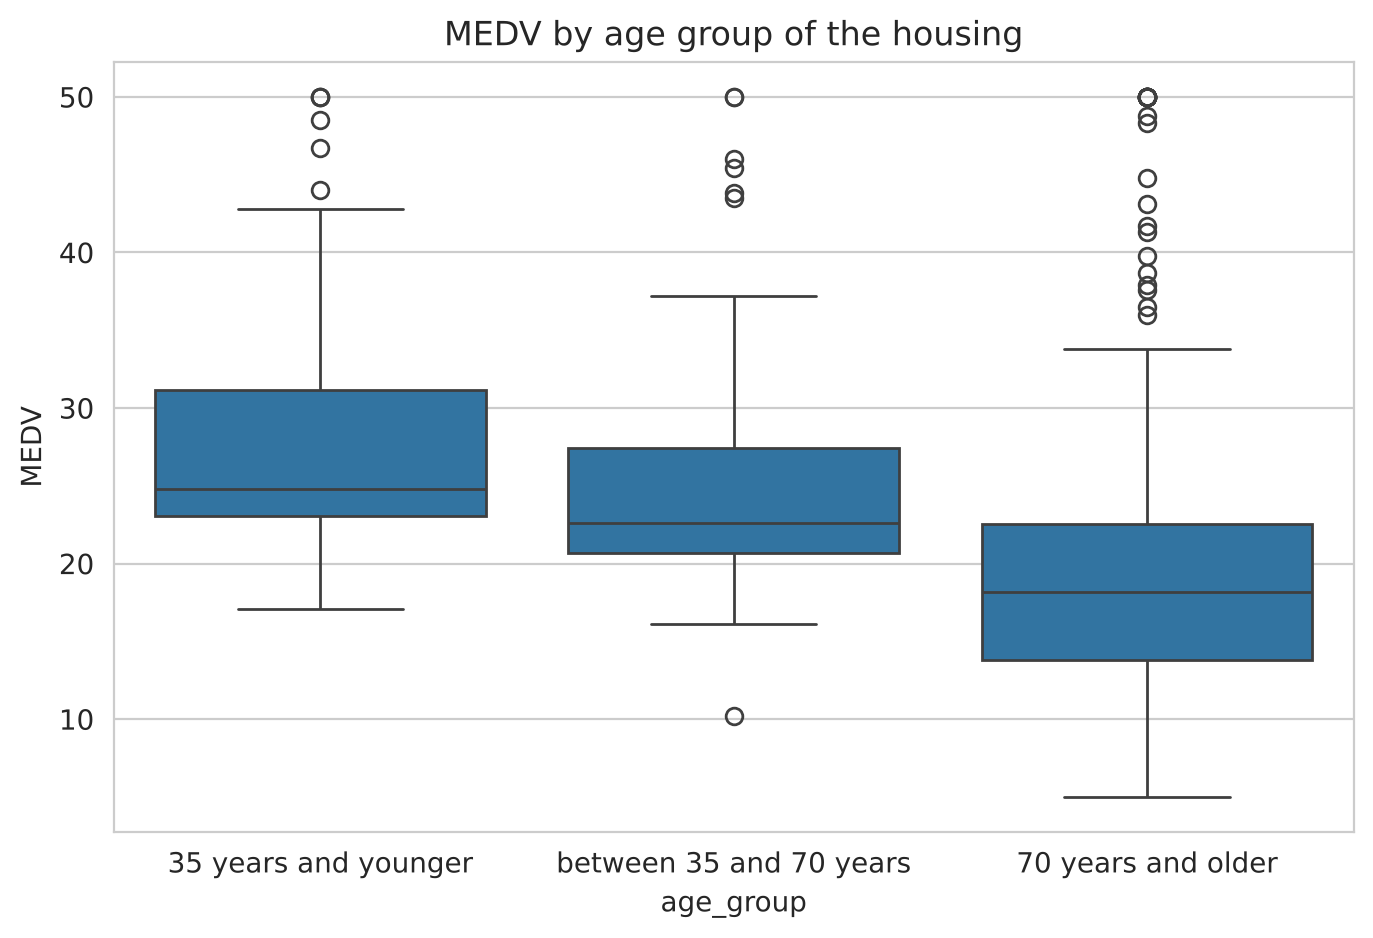

In [14]:
boston_df['age_group'] = pd.cut(
    boston_df['AGE'], bins=[0, 35, 70, 100],
    labels=['35 years and younger', 'between 35 and 70 years', '70 years and older'])
plt.figure(figsize=(8,5))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
plt.title('MEDV by age group of the housing')
plt.show()

**Interpretation:** Median home value falls as the age of the housing increases. Homes aged 35 years and younger have the highest median MEDV; the oldest group has the lowest.

### 3.6 Bar plot: Charles River (CHAS)

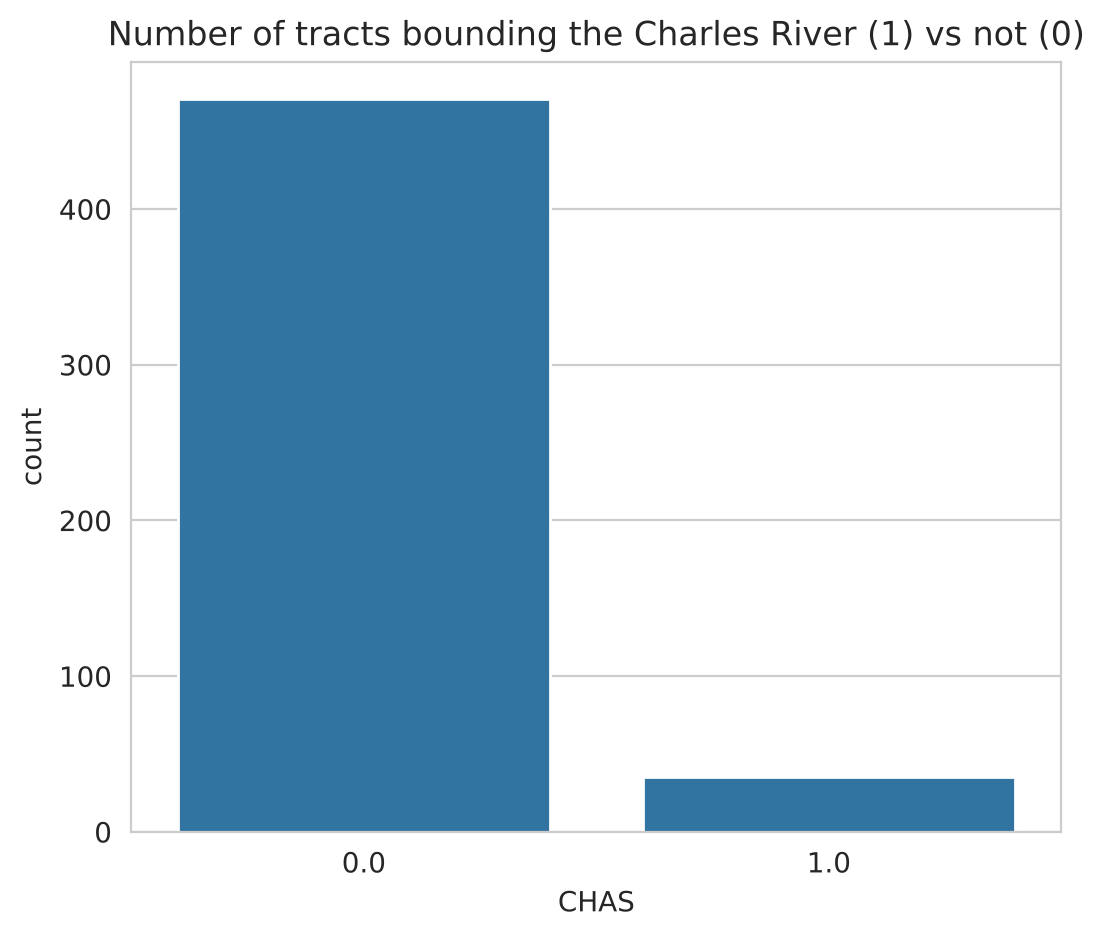

In [15]:
plt.figure(figsize=(6,5))
sns.countplot(x='CHAS', data=boston_df)
plt.title('Number of tracts bounding the Charles River (1) vs not (0)')
plt.show()

**Interpretation:** The vast majority of tracts do not border the Charles River (CHAS = 0); only about 35 do.

## Task 4: Hypothesis testing

### 4.1 Levene's test (equality of variance)

**H0:** the variances of MEDV are equal for tracts bounding the Charles River and those that do not.

**H1:** the variances are different.

In [16]:
a = boston_df[boston_df['CHAS'] == 0]['MEDV']
b = boston_df[boston_df['CHAS'] == 1]['MEDV']
scipy.stats.levene(a, b, center='mean')

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.0032381193676394252))

**Conclusion:** At the 0.05 level, if the p-value is below 0.05 we reject H0 and conclude the variances differ (not equal).

### 4.2 T-test: MEDV for houses bounding vs not bounding the Charles River

**H0:** the mean MEDV is the same for both groups.

**H1:** the mean MEDV differs between the two groups.

In [17]:
scipy.stats.ttest_ind(a, b, equal_var=False)

TtestResult(statistic=np.float64(-3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))

**Conclusion:** The p-value is far below 0.05, so we reject H0: there is a significant difference in median home value between tracts that bound the Charles River and those that do not.

### 4.3 ANOVA: MEDV across age groups

**H0:** the mean MEDV is equal across all three age groups.

**H1:** at least one age group has a different mean MEDV.

In [18]:
g1 = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
g2 = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
g3 = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']
scipy.stats.f_oneway(g1, g2, g3)

F_onewayResult(statistic=np.float64(36.40764999196599), pvalue=np.float64(1.7105011022701404e-15))

**Conclusion:** The p-value is far below 0.05, so we reject H0: at least one age group has a different mean MEDV.

### 4.4 Pearson correlation: NOX and INDUS

**H0:** there is no relationship between NOX and INDUS.

**H1:** there is a relationship between NOX and INDUS.

In [19]:
scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

PearsonRResult(statistic=np.float64(0.7636514469209154), pvalue=np.float64(7.913361061239639e-98))

**Conclusion:** r is strongly positive and the p-value is far below 0.05, so we reject H0: NOX and INDUS are significantly (positively) correlated.

### 4.5 Regression: impact of the weighted distance to employment centres (DIS) on MEDV

**H0:** the slope (DIS coefficient) is 0.

**H1:** the slope is not 0.

In [20]:
X = sm.add_constant(boston_df['DIS'])
model = sm.OLS(boston_df['MEDV'], X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        03:38:15   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Conclusion:** The DIS coefficient (slope) is about 1.09 with a p-value far below 0.05, so we reject H0. Each one-unit increase in weighted distance to the employment centres is associated with an average increase of about 1.09 (i.e. $1,090) in median home value.